# Phase 2A · 01 · Unified random forest

**Goal:** train the paper's unified CRC classifier, a random forest on all 27 studies, and check that it reaches the paper's AUC of 0.84.

**What this notebook shows**
- What cross-validation is, and why this dataset needs the *grouped* (study-blocked) kind.
- How 10 repeats of 10-fold cross-validation give every sample 10 predictions, and how they are combined.
- What AUC measures, and how our AUC compares with the paper's.
- Why we land below 0.84 with study-blocked folds, and how random folds reproduce the paper's number.

## Setup

Inputs come from notebook 1/03: the normalized feature matrix (5,966 samples × 333 genera) and the labels.

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold

SEED = 2000
PAPER_AUC = 0.84
print("SEED =", SEED)

SEED = 2000


In [2]:
def find_project_root() -> Path:
    """Walk up from the current folder until we find the one that holds requirements.txt."""
    folder = Path.cwd()
    while not (folder / "requirements.txt").exists():
        if folder.parent == folder:
            raise FileNotFoundError("Could not find the project root (no requirements.txt above this folder).")
        folder = folder.parent
    return folder


PROJECT_ROOT = find_project_root()
PROCESSED = PROJECT_ROOT / "data" / "processed"
FIGURES = PROJECT_ROOT / "results" / "figures"
TABLES = PROJECT_ROOT / "results" / "tables"
NOTEBOOK_PREFIX = "p2a_01"
figure_number = 0


def show_figure(fig: plt.Figure, name: str, caption: str) -> None:
    global figure_number
    figure_number += 1
    FIGURES.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIGURES / f"{NOTEBOOK_PREFIX}_{name}.png", dpi=150, bbox_inches="tight")
    plt.show()
    display(Markdown(f"**Figure {figure_number}.** {caption}"))

In [3]:
features = pd.read_parquet(PROCESSED / "features_unified.parquet")
labels = pd.read_csv(PROCESSED / "labels.csv", index_col="Sample_ID", dtype={"Sample_ID": str})
assert features.index.equals(labels.index), "features and labels must be in the same row order"

X = features
y = labels["label"].to_numpy()
groups = labels["Cohort"].to_numpy()
print(f"X: {X.shape}, CRC: {y.sum():,}, controls: {(y == 0).sum():,}, studies: {len(set(groups))}")

X: (5966, 333), CRC: 2,983, controls: 2,983, studies: 27


## 1. Cross-validation, and why it must be grouped by study

To measure how well a model works on data it has never seen, we hide part of the data during training and test on it afterwards. **K-fold cross-validation** does this systematically: split the samples into 10 parts (folds), train on 9 and test on the 10th, and repeat until every fold has been the test set once. Every sample then has exactly one prediction made by a model that never saw it.

The catch here is that samples from the same study share measurement quirks. If a study's samples are spread across training and test folds, the model can recognize the study instead of the disease, and the score looks better than it really is. That is a form of **data leakage**. The paper's Methods therefore block by study: "samples from a study would either all be in the training or the testing set".

scikit-learn's `StratifiedGroupKFold` does exactly that. *Group* keeps each study whole, and *stratified* tries to keep the CRC/control ratio similar across folds. A toy example with 6 samples from 3 studies and 3 folds:

In [4]:
toy_y = np.array([1, 0, 1, 0, 1, 0])
toy_groups = np.array(["study_A", "study_A", "study_B", "study_B", "study_C", "study_C"])
for fold, (train_idx, test_idx) in enumerate(StratifiedGroupKFold(n_splits=3).split(np.zeros(6), toy_y, toy_groups), start=1):
    print(f"fold {fold}: train on {sorted(set(toy_groups[train_idx].tolist()))}, test on {sorted(set(toy_groups[test_idx].tolist()))}")

fold 1: train on ['study_B', 'study_C'], test on ['study_A']
fold 2: train on ['study_A', 'study_C'], test on ['study_B']
fold 3: train on ['study_A', 'study_B'], test on ['study_C']


## 2. Ten repeats of ten folds

How studies land in folds is random, and with only 27 studies one unlucky split can move the score. So the paper repeats the whole 10-fold procedure 10 times with different random splits, which gives 100 trained models and 10 predictions per sample.

In [5]:
def make_blocked_folds(
    y: np.ndarray, groups: np.ndarray, n_splits: int = 10, n_repeats: int = 10, seed: int = SEED
) -> list[list[tuple[np.ndarray, np.ndarray]]]:
    """One list of (train_idx, test_idx) pairs per repeat. Studies are never split between train and test."""
    repeats = []
    for repeat in range(n_repeats):
        splitter = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed + repeat)
        repeats.append(list(splitter.split(np.zeros(len(y)), y, groups)))
    return repeats


folds = make_blocked_folds(y, groups)
train_sizes = [len(train_idx) for repeat in folds for train_idx, _ in repeat]
test_sizes = [len(test_idx) for repeat in folds for _, test_idx in repeat]
print(f"{len(train_sizes)} folds. Average train size {np.mean(train_sizes):,.0f} (paper: 5,369), average test size {np.mean(test_sizes):,.0f} (paper: 597)")

100 folds. Average train size 5,369 (paper: 5,369), average test size 597 (paper: 597)


The averages match the paper's by construction: every sample is tested exactly once per repeat, so the average test fold is always 5,966 / 10. The individual folds are very uneven, because whole studies of very different sizes are dealt into them.

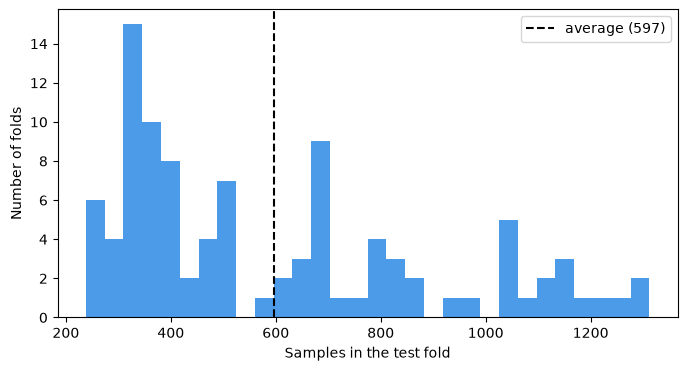

**Figure 1.** Across the 100 study-blocked test folds, sizes range from 238 to 1,312 samples (average 597). A fold's size depends on which studies it receives: the largest study alone contributes 1,026 balanced samples.

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(test_sizes, bins=30, color="#4C9BE8")
ax.axvline(np.mean(test_sizes), color="black", linestyle="--", label=f"average ({np.mean(test_sizes):.0f})")
ax.set_xlabel("Samples in the test fold")
ax.set_ylabel("Number of folds")
ax.legend()

show_figure(
    fig,
    "fold_sizes",
    f"Across the {len(test_sizes)} study-blocked test folds, sizes range from {min(test_sizes)} to {max(test_sizes):,} samples "
    f"(average {np.mean(test_sizes):.0f}). A fold's size depends on which studies it receives: the largest study alone "
    f"contributes {pd.Series(groups).value_counts().max():,} balanced samples.",
)

## 3. The model: a random forest

A random forest is a vote of many decision trees. Each tree is trained on a random resample of the training data and, at every split, may only choose among a random subset of the features. That randomness makes the trees disagree in useful ways, and their average is more reliable than any single tree. The share of trees voting "CRC" is the model's predicted probability.

Settings: 200 trees and √(number of features) candidate features per split, √333 ≈ 18. The paper's text does not state them. They are what the authors wrote in their code, and √p is also the default of `ranger`, the R library they used.

In [7]:
def make_forest(seed: int) -> RandomForestClassifier:
    return RandomForestClassifier(n_estimators=200, max_features="sqrt", n_jobs=-1, random_state=seed)


def cross_validated_predictions(X: pd.DataFrame, y: np.ndarray, folds) -> np.ndarray:
    """Out-of-fold CRC probability for every sample, one column per repeat."""
    predictions = np.full((len(y), len(folds)), np.nan)
    for repeat, repeat_folds in enumerate(folds):
        for train_idx, test_idx in repeat_folds:
            model = make_forest(SEED)
            model.fit(X.iloc[train_idx], y[train_idx])
            predictions[test_idx, repeat] = model.predict_proba(X.iloc[test_idx])[:, 1]
    return predictions


start = time.perf_counter()
predictions = cross_validated_predictions(X, y, folds)
print(f"Trained {sum(len(r) for r in folds)} forests in {time.perf_counter() - start:.0f} s")

Trained 100 forests in 90 s


## 4. AUC

Each sample now has 10 predicted probabilities, one per repeat. The paper's Methods combine them with the **median**.

**AUC** (area under the ROC curve) answers one question: if we pick one random CRC sample and one random control, how often does the model give the CRC sample the higher score? 0.5 is coin-flipping and 1.0 is perfect. The ROC curve shows the trade-off behind it. Lowering the threshold for calling a sample "CRC" catches more cancers (true positive rate) but also flags more healthy people (false positive rate).

In [8]:
median_prediction = np.median(predictions, axis=1)
auc_median = roc_auc_score(y, median_prediction)
auc_per_repeat = [roc_auc_score(y, predictions[:, repeat]) for repeat in range(predictions.shape[1])]

print(f"AUC (median over repeats): {auc_median:.3f}   paper: {PAPER_AUC}")
print(f"AUC of the single repeats: {min(auc_per_repeat):.3f} to {max(auc_per_repeat):.3f}")

AUC (median over repeats): 0.810   paper: 0.84
AUC of the single repeats: 0.804 to 0.808


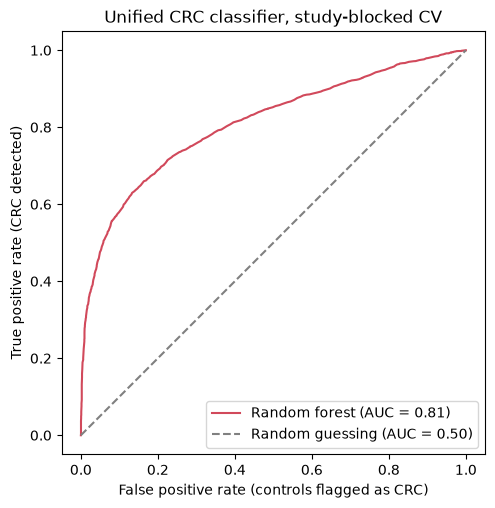

**Figure 2.** ROC curve of the median predictions for 5,966 samples (2,983 CRC, 2,983 controls). AUC = 0.810, against 0.84 in the paper (difference -0.030). The 10 single repeats range from 0.804 to 0.808. At a 10% false positive rate the model detects 58% of CRC samples.

In [9]:
false_positive_rate, true_positive_rate, _ = roc_curve(y, median_prediction)

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot(false_positive_rate, true_positive_rate, color="#D1495B", label=f"Random forest (AUC = {auc_median:.2f})")
ax.plot([0, 1], [0, 1], color="grey", linestyle="--", label="Random guessing (AUC = 0.50)")
ax.set_xlabel("False positive rate (controls flagged as CRC)")
ax.set_ylabel("True positive rate (CRC detected)")
ax.set_title("Unified CRC classifier, study-blocked CV")
ax.legend(loc="lower right")
ax.set_aspect("equal")

at_90_specificity = true_positive_rate[np.searchsorted(false_positive_rate, 0.10, side="right") - 1]
show_figure(
    fig,
    "roc_unified",
    f"ROC curve of the median predictions for {len(y):,} samples (2,983 CRC, 2,983 controls). AUC = {auc_median:.3f}, "
    f"against {PAPER_AUC} in the paper (difference {auc_median - PAPER_AUC:+.3f}). The 10 single repeats range from "
    f"{min(auc_per_repeat):.3f} to {max(auc_per_repeat):.3f}. At a 10% false positive rate the model detects "
    f"{at_90_specificity:.0%} of CRC samples.",
)

## 5. Where does the paper's 0.84 come from?

Our study-blocked AUC is below the paper's 0.84. The paper's text says its folds were blocked by study, but the authors' script for this model (`03.Train.unified.crc.model.R`) never passes the study column to the fold maker, so its folds are random.

To test whether that explains the gap, we run the exact same pipeline again and change one thing only: samples are dealt into folds at random (`StratifiedKFold`), so a study's samples end up in both training and test folds. Same samples, same 333 features, same forest, same median over 10 repeats.

In [10]:
def make_random_folds(y: np.ndarray, n_splits: int = 10, n_repeats: int = 10, seed: int = SEED) -> list[list[tuple[np.ndarray, np.ndarray]]]:
    """Same as make_blocked_folds, but ignores studies: samples are dealt into folds at random."""
    repeats = []
    for repeat in range(n_repeats):
        splitter = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed + repeat)
        repeats.append(list(splitter.split(np.zeros(len(y)), y)))
    return repeats


random_folds = make_random_folds(y)
studies_split = np.mean([len(set(groups[train_idx]) & set(groups[test_idx])) for repeat in random_folds for train_idx, test_idx in repeat])
print(f"With random folds, on average {studies_split:.1f} studies appear in both the training and the test part of a fold.")

start = time.perf_counter()
predictions_random = cross_validated_predictions(X, y, random_folds)
print(f"Trained {sum(len(r) for r in random_folds)} forests in {time.perf_counter() - start:.0f} s")

auc_random = roc_auc_score(y, np.median(predictions_random, axis=1))
auc_random_per_repeat = [roc_auc_score(y, predictions_random[:, repeat]) for repeat in range(predictions_random.shape[1])]
print(f"AUC with random folds: {auc_random:.3f}   with study-blocked folds: {auc_median:.3f}   paper: {PAPER_AUC}")

With random folds, on average 26.9 studies appear in both the training and the test part of a fold.


Trained 100 forests in 93 s
AUC with random folds: 0.845   with study-blocked folds: 0.810   paper: 0.84


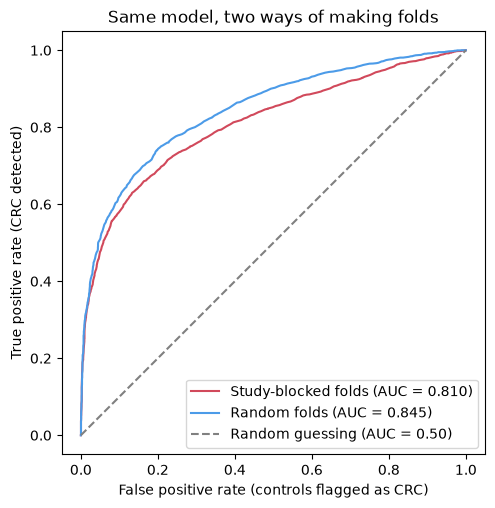

**Figure 3.** With random folds the AUC is 0.845 (+0.005 from the paper's 0.84), with single repeats from 0.838 to 0.842. With study-blocked folds it is 0.810 (0.804 to 0.808). The repeats never overlap, so the gap of 0.035 comes from the fold method, not from chance. In random folds, on average 26.9 studies sit on both sides of a split, and recognizing a study's fingerprint inflates the score.

In [11]:
unified_auc = pd.DataFrame([
    {"cv": "study-blocked (paper's text)", "auc": round(auc_median, 4), "paper_auc": PAPER_AUC},
    {"cv": "random (authors' code)", "auc": round(auc_random, 4), "paper_auc": PAPER_AUC},
])
TABLES.mkdir(parents=True, exist_ok=True)
unified_auc.to_csv(TABLES / "unified_auc.csv", index=False)

fpr_random, tpr_random, _ = roc_curve(y, np.median(predictions_random, axis=1))
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot(false_positive_rate, true_positive_rate, color="#D1495B", label=f"Study-blocked folds (AUC = {auc_median:.3f})")
ax.plot(fpr_random, tpr_random, color="#4C9BE8", label=f"Random folds (AUC = {auc_random:.3f})")
ax.plot([0, 1], [0, 1], color="grey", linestyle="--", label="Random guessing (AUC = 0.50)")
ax.set_xlabel("False positive rate (controls flagged as CRC)")
ax.set_ylabel("True positive rate (CRC detected)")
ax.set_title("Same model, two ways of making folds")
ax.legend(loc="lower right")
ax.set_aspect("equal")

show_figure(
    fig,
    "roc_blocked_vs_random",
    f"With random folds the AUC is {auc_random:.3f} ({auc_random - PAPER_AUC:+.3f} from the paper's {PAPER_AUC}), with single repeats "
    f"from {min(auc_random_per_repeat):.3f} to {max(auc_random_per_repeat):.3f}. With study-blocked folds it is {auc_median:.3f} "
    f"({min(auc_per_repeat):.3f} to {max(auc_per_repeat):.3f}). The repeats never overlap, so the gap of "
    f"{auc_random - auc_median:.3f} comes from the fold method, not from chance. In random folds, on average "
    f"{studies_split:.1f} studies sit on both sides of a split, and recognizing a study's fingerprint inflates the score.",
)

**Conclusion.** The paper's 0.84 is reproduced by random folds. Measured the way the paper's text describes, with every study held out whole, the same classifier scores about 0.81. We keep the study-blocked result as our main number, because it follows the paper's stated method and it answers the real question: how well does the model work on a study it has never seen?

## 6. Notes on the authors' code

We follow the paper's text. Three places where the authors' R code does something the text does not describe:

1. **Repeats are averaged, not medianed.** SIAMCAT's `evaluate.predictions` hard-codes the mean, while the Methods say median.
2. **The 200 trees were never used.** `train_model_rf` passes `num.trees = 200`, but SIAMCAT reads a parameter called `ntree`. The value is silently ignored, and SIAMCAT instead tunes the number of trees (100 to 1,000) and the features per split inside every fold.
3. **The unified script does not block by study.** `03.Train.unified.crc.model.R` calls `train_model_rf` without `block_label`, so its folds are random, while the Methods say blocked.

Points 1 and 2 are not replicated here. Point 3 is tested in section 5, and it explains the gap to 0.84.

## 7. Checks

In [12]:
for repeat in folds:
    for train_idx, test_idx in repeat:
        assert set(groups[train_idx]).isdisjoint(groups[test_idx])
        assert set(y[test_idx]) == {0, 1}
assert predictions.shape == (5966, 10)
assert not np.isnan(predictions).any()
assert any(set(groups[tr]) & set(groups[te]) for repeat in random_folds for tr, te in repeat)
assert abs(auc_random - 0.84) <= 0.02
assert auc_median < auc_random
assert 0.5 < auc_median < 1
print("All checks passed.")

All checks passed.


## What we learned

- With study-blocked 10×10 cross-validation, as the paper's Methods describe, the unified random forest reaches an AUC of **0.810**. Every single repeat lands between 0.804 and 0.808, so the result is stable.
- The paper reports 0.84. Running the identical pipeline with random folds, as the authors' script actually does, gives **0.845** and reproduces it.
- The 0.035 gap is leakage. With random folds almost every study (26.9 of 27 on average) has samples on both sides of a split, so the model gets credit for recognizing studies, not only cancer.
- Our main number is the study-blocked 0.810, because it follows the paper's text and measures what matters: performance on a study the model has never seen. All later comparisons (Phase 2B, Phase 3) use study-blocked folds.
- At a 10% false positive rate, the model detects 58% of CRC samples.